In [60]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [125]:
def p_from_mu(k,n,mu_b,mu,gam):
    result = k*(((n**(gam-1))+(((gam-1)/(k*gam))*(mu-mu_b)))**(gam/(gam-1)))
    return result
def k(p_initial,n_initial,gam):
    result = p_initial/(n_initial**gam)
    return result
def n_from_p(p,k,gam):
    result = (p/k)**(1/gam)
    return result
def e_from_p(p,n,mu):
    result = (n*mu)-p
    return result

p_initial_had = 3.542
mu_initial_had = 977.5
n0 = 0.16 #nuclear saturation density
n_intial_had = 1.1*n0
gam = 2
k_1=k(p_initial_had,n_intial_had,gam)

mu_had = np.linspace(977.5,1800,100)

p_had = p_from_mu(k_1,n_intial_had,mu_initial_had,mu_had,gam)

n_had = n_from_p(p_had,k_1,gam)


In [126]:
k_1

114.34659090909088

In [127]:
n_had[25]

1.084212560386474

In [128]:
p_had[:25]

array([  3.542     ,   5.15513229,   7.07008471,   9.28685727,
        11.80544996,  14.62586278,  17.74809574,  21.17214883,
        24.89802206,  28.92571542,  33.25522891,  37.88656253,
        42.81971629,  48.05469019,  53.59148421,  59.43009838,
        65.57053267,  72.0127871 ,  78.75686166,  85.80275636,
        93.15047119, 100.80000615, 108.75136125, 117.00453648,
       125.55953184])

In [129]:
mu_had[:25]

array([ 977.5       ,  985.80808081,  994.11616162, 1002.42424242,
       1010.73232323, 1019.04040404, 1027.34848485, 1035.65656566,
       1043.96464646, 1052.27272727, 1060.58080808, 1068.88888889,
       1077.1969697 , 1085.50505051, 1093.81313131, 1102.12121212,
       1110.42929293, 1118.73737374, 1127.04545455, 1135.35353535,
       1143.66161616, 1151.96969697, 1160.27777778, 1168.58585859,
       1176.89393939])

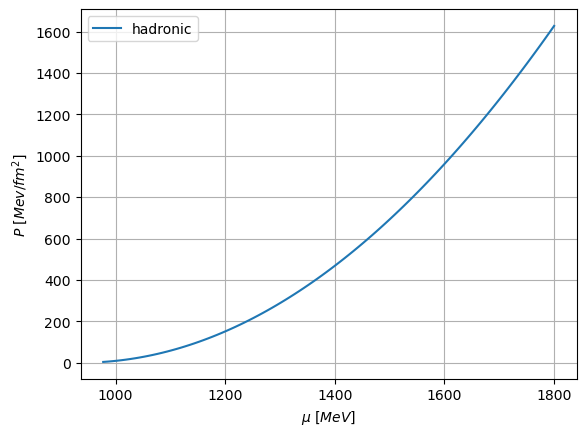

In [130]:
plt.plot(mu_had, p_had, label = "hadronic")
#plt.plot(mu_quark, P_3_all, label = "quark")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
#plt.xlim([950,1400])
#plt.ylim([0,200])
plt.grid()

In [131]:
n_had[25]

1.084212560386474

In [132]:
p_had[25]

134.41634733811557

In [133]:
mu_had[25]

1185.2020202020203

In [134]:
p_initial_quark = p_had[25]
mu_b_quark = mu_had[25]
n_pt = n_had[25]

delta_n = 8*n_pt

n_intial_quark = n_pt + delta_n

In [135]:
n_had[25]/n0

6.7763285024154625

In [136]:
gam = 2
k_2=k(p_initial_quark,n_intial_quark,gam) 

mu_quark = np.linspace(mu_b_quark,1500,100)

p_quark = p_from_mu(k_2,n_intial_quark,mu_b_quark,mu_quark,gam)

n_quark = n_from_p(p_quark,k_2,gam)

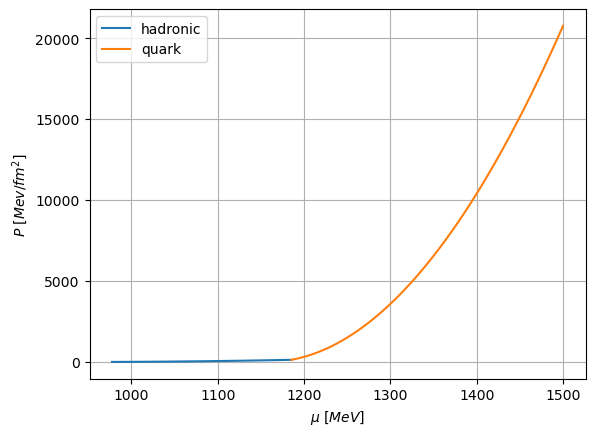

In [137]:
plt.plot(mu_had[:26], p_had[:26], label = "hadronic")
plt.plot(mu_quark, p_quark, label = "quark")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [140]:
n_quark

array([  9.75791304,  10.88414681,  12.01038058,  13.13661434,
        14.26284811,  15.38908187,  16.51531564,  17.64154941,
        18.76778317,  19.89401694,  21.02025071,  22.14648447,
        23.27271824,  24.398952  ,  25.52518577,  26.65141954,
        27.7776533 ,  28.90388707,  30.03012084,  31.1563546 ,
        32.28258837,  33.40882213,  34.5350559 ,  35.66128967,
        36.78752343,  37.9137572 ,  39.03999097,  40.16622473,
        41.2924585 ,  42.41869226,  43.54492603,  44.6711598 ,
        45.79739356,  46.92362733,  48.0498611 ,  49.17609486,
        50.30232863,  51.42856239,  52.55479616,  53.68102993,
        54.80726369,  55.93349746,  57.05973123,  58.18596499,
        59.31219876,  60.43843252,  61.56466629,  62.69090006,
        63.81713382,  64.94336759,  66.06960136,  67.19583512,
        68.32206889,  69.44830265,  70.57453642,  71.70077019,
        72.82700395,  73.95323772,  75.07947149,  76.20570525,
        77.33193902,  78.45817278,  79.58440655,  80.71

In [138]:
e_had = (mu_had*n_had)-p_had
e_quark = (mu_quark*n_quark)-p_quark

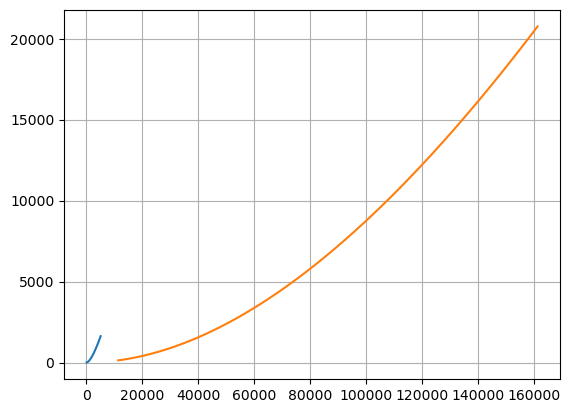

In [139]:
plt.plot(e_had, p_had, label = "hadronic")
plt.plot(e_quark, p_quark, label = "quark")
plt.grid()

In [25]:
n0 = 0.16 # Nuclear saturation density.
n_pt_array = np.linspace(1.1,8,10)
n_pt_array = n_pt_array*n0
delta_n_array = np.linspace(0,9.09,10)
delta_n_array = delta_n_array*n_pt_array

In [26]:
def mu_from_p(p,k,gam,n_intial,mu_initial):
    term1 = (((p**((gam-1)/gam))/k)-n_intial**(gam-1))*((k*gam)/gam-1)
    term2 = mu_initial
    result = term1 +term2
    return result

def p_from_n(n,k,gam):
    result = k*((n)**gam)
    return result

def p_from_mu(k,n,mu_b,mu,gam):
    result = k*(((n**(gam-1))+((gam-1)/(k*gam)*(mu-mu_b)))**(gam/(gam-1)))
    return result

def k(p_initial,n_initial,gam):
    result = p_initial/(n_initial**gam)
    return result

def n_from_p(p,k,gam):
    result = (p/k)**(1/gam)
    return result

def e_from_p(p,n,mu):
    result = (n*mu)-p
    return result

In [27]:
import itertools
import numpy as np

def mu_from_p(p,k,gam,n_intial,mu_initial):
    term1 = (((p**((gam-1)/gam))/k)-n_intial**(gam-1))*((k*gam)/gam-1)
    term2 = mu_initial
    result = term1 +term2
    return result

def p_from_n(n,k,gam):
    result = k*((n)**gam)
    return result

def p_from_mu(k,n,mu_b,mu,gam):
    result = k*(((n**(gam-1))+((gam-1)/(k*gam)*(mu_b-mu)))**(gam/(gam-1)))
    return result

def k(p_initial,n_initial,gam):
    result = p_initial/(n_initial**gam)
    return result

def n_from_p(p,k,gam):
    result = (p/k)**(1/gam)
    return result

def e_from_p(p,n,mu):
    result = (n*mu)-p
    return result

n0 = 0.16  # Nuclear saturation density
n_pt_array = np.linspace(1.1, 8, 10) * n0
gam_had_array = np.linspace(1.1, 4, 10)
gam_quark_array = np.linspace(0.5, 4, 10)

mu, p, e = [], [], []

# Combine the arrays into one loop using itertools.product
for n_pt, gam_had, gam_quark in itertools.product(n_pt_array, gam_had_array, gam_quark_array):

    # Calculate delta_n_array for the current n_pt
    delta_n_array = np.linspace(0, 9.09, 100) * n_pt

    # Iterate over delta_n_array
    for delta_n in delta_n_array:
        p_initial_had = 3.542
        mu_initial_had = 977.5

        n_initial_had = 1.1 * n0
        k_had = k(p_initial_had, n_initial_had, gam_had)

        # Pressure and chemical potential at phase transition
        p_pt = p_from_n(n_pt, k_had, gam_had)
        mu_pt = mu_from_p(p_pt, k_had, gam_had, n_initial_had, mu_initial_had)

        # Hadronic phase
        mu_had = np.linspace(mu_initial_had, mu_pt, 100)
        p_had = p_from_mu(k_had, n_initial_had, mu_initial_had, mu_had, gam_had)
        n_had = n_from_p(p_had, k_had, gam_had)
        e_had = e_from_p(p_had, n_had, mu_had)

        # Quark phase
        n_initial_quark = n_pt + delta_n
        k_quark = k(p_pt, n_initial_quark, gam_quark)

        mu_quark = np.linspace(mu_pt, 1500, 100)
        p_quark = p_from_mu(k_quark, n_initial_quark, mu_pt, mu_quark, gam_quark)
        n_quark = n_from_p(p_quark, k_quark, gam_quark)
        e_quark = e_from_p(p_quark, n_quark, mu_quark)

        # Combine hadronic and quark phases
        mu_total = np.concatenate((mu_had, mu_quark))
        p_total = np.concatenate((p_had, p_quark))
        e_total = np.concatenate((e_had, e_quark))

        mu.append(mu_total)
        p.append(p_total)
        e.append(e_total)


/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_20389/2524777285.py:15: RuntimeWarning: invalid value encountered in power
  result = k*(((n**(gam-1))+((gam-1)/(k*gam)*(mu_b-mu)))**(gam/(gam-1)))


In [28]:
len(mu)

100000

In [29]:
import matplotlib.pyplot as plt

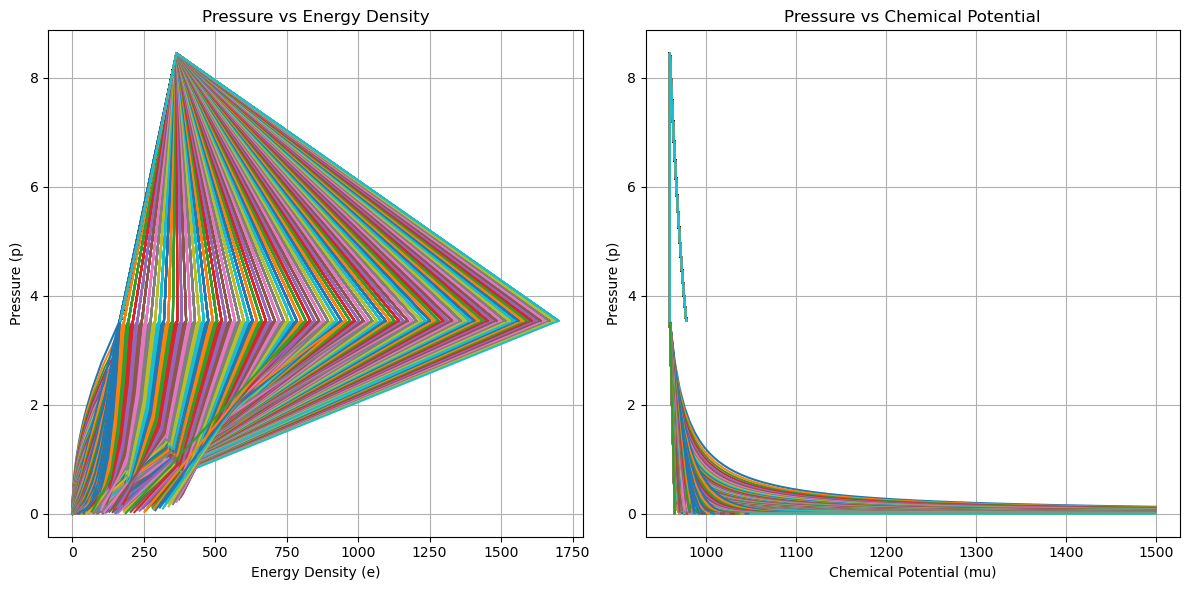

In [30]:
# Create a 2x1 grid of subplots to include both curves in one plot
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# After the loop, plot concatenated data
for i in range(1000):
    # Plot 1: Pressure vs Energy Density
    axes[0].plot(e[i], p[i], label=f"Curve {i+1}")

    # Plot 2: Pressure vs Chemical Potential
    axes[1].plot(mu[i], p[i], label=f"Curve {i+1}")

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0].set_title('Pressure vs Energy Density')
axes[0].set_xlabel('Energy Density (e)')
axes[0].set_ylabel('Pressure (p)')
axes[0].grid(True)

# Plot 2: Pressure vs Chemical Potential
axes[1].set_title('Pressure vs Chemical Potential')
axes[1].set_xlabel('Chemical Potential (mu)')
axes[1].set_ylabel('Pressure (p)')
axes[1].grid(True)

# Optionally add legends (uncomment to show)
# axes[0].legend()
# axes[1].legend()

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()


In [35]:
def mu_from_p(p,k,gam,n_intial,mu_initial):
    term1 = (((p/k)**((gam-1)/gam))-n_intial**(gam-1))*((k*gam)/gam-1)
    term2 = mu_initial
    result = term1 +term2
    return result

def p_from_n(n,k,gam):
    result = k*((n)**gam)
    return result

def p_from_mu(k,n,mu_b,mu,gam):
    mu = k*(((n**(gam-1))+(((gam-1)/(k*gam))*(mu-mu_b)))**(gam/(gam-1)))
    return mu

def k(p_initial,n_initial,gam):
    result = p_initial/(n_initial**gam)
    return result
def k(p_initial,n_initial,gam):
    result = p_initial/(n_initial**gam)
    return result

def n_from_p(p,k,gam):
    result = (p/k)**(1/gam)
    return result

def e_from_p(p,n,mu):
    result = (n*mu)-p
    return result

In [117]:
p_initial_had = 3.542
mu_initial_had = 977.5

n0 = 0.16
n_intial_had = 1.1*n0
gam_had = 2
k_had=k(p_initial_had,n_intial_had,gam_had)

n_pt = 6.7*n0

n_had = np.linspace(n_initial_had,n_pt,100)
p_had = p_from_n(n_had,k_had,gam_had)
mu_had = mu_from_p(p_had,k_had,gam_had,n_initial_had,mu_initial_had)

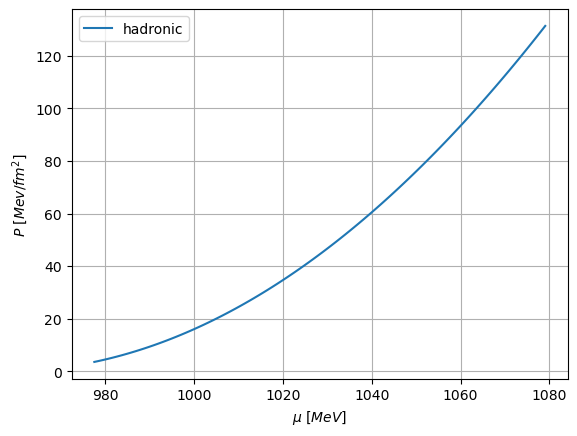

In [118]:
plt.plot(mu_had, p_had, label = "hadronic")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [143]:
gam_quark = 2
delta_n = 8*n_pt
mu_initial_quark = mu_had[-1]
n_initial_quark = n_pt + delta_n
k_quark=k(p_had[-1],n_initial_quark,gam_quark)

n_quark = np.linspace(n_initial_quark,25,100)
p_quark = p_from_n(n_quark,k_quark,gam_quark)
mu_quark = mu_from_p(p_quark,k_quark,gam_quark,n_initial_quark,mu_initial_quark)

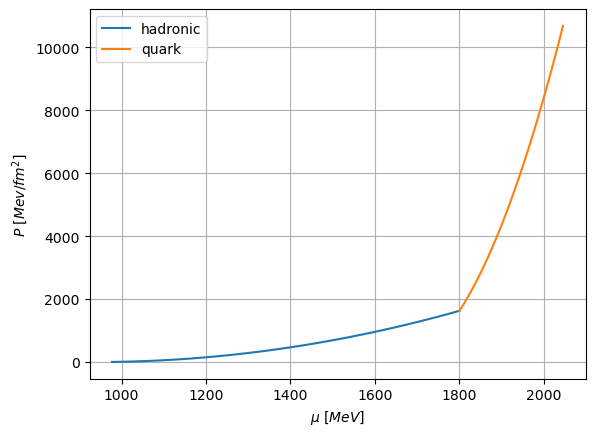

In [144]:
plt.plot(mu_had, p_had, label = "hadronic")
plt.plot(mu_quark, p_quark, label = "quark")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [ ]:
k_2=k(p_initial_quark,n_intial_quark,gam) 

mu_quark = np.linspace(mu_b_quark,1500,100)

p_quark = p_from_mu(k_2,n_intial_quark,mu_b_quark,mu_quark,gam)

n_quark = n_from_p(p_quark,k_2,gam)

In [93]:
k_2

1.4116863075196404

In [38]:
p_initial_had = 3.542
mu_initial_had = 977.5

n_initial_had = 1.1 * n0
k_had = k(p_initial_had, n_initial_had, gam_had)

# Pressure and chemical potential at phase transition
p_pt = p_from_n(n_pt, k_had, gam_had)
mu_pt = mu_from_p(p_pt, k_had, gam_had, n_initial_had, mu_initial_had)

# Hadronic phase
mu_had = np.linspace(mu_initial_had, mu_pt, 100)
p_had = np.linspace(p_initial_had,p_pt,100)
n_had = n_from_p(p_had, k_had, gam_had)
e_had = e_from_p(p_had, n_had, mu_had)

# Quark phase
n_initial_quark = n_pt + delta_n
k_quark = k(p_pt, n_initial_quark, gam_quark)

mu_quark = np.linspace(mu_pt, 1100, 100)
p_quark = p_from_mu(k_quark, n_initial_quark, mu_pt, mu_quark, gam_quark)
n_quark = n_from_p(p_quark, k_quark, gam_quark)
e_quark = e_from_p(p_quark, n_quark, mu_quark)

# Combine hadronic and quark phases
mu_total = np.concatenate((mu_had, mu_quark))
p_total = np.concatenate((p_had, p_quark))
e_total = np.concatenate((e_had, e_quark))